# The late count

From `FINDINGS.md`:

> Report 5, published November 4, is the last report on which No led Measure B. Comparing each precinct's votes on that report with its votes on Report 11 separates the 206,320 ballots counted by November 4 from the 145,182 counted since.
>
> The votes counted after November 4 were more yes on Measures B and I, and more no on Measures D and G, than the votes counted before. Measure B was 49.96 percent yes through November 4 and 56.6 percent yes among the votes counted since. Measure I went from 45.3 percent to 52.8 percent, Measure D from 57.5 percent to 49.3 percent, and Measure G from 36.4 percent to 31.3 percent.
>
> The change happened inside precincts. It did not come from some parts of the city reporting later than others. Comparing precincts with at least 50 votes on a measure by November 4 and at least 30 since, the later votes were more yes on Measure B in 439 of 506 precincts and on Measure I in 463 of 504. They were less yes on Measure D in 474 of 506 and on Measure G in 419 of 506. The data does not say who cast the later ballots or why they differ.
>
> The lean grew stronger as the count went on. On Measure B, the votes added by the November 5 through November 7 reports were 54.1 to 56.2 percent yes, and the votes added by the November 8 through November 10 reports were 67.0 to 69.5 percent yes. Measure I's added votes went from 49.9–52.4 percent yes to 63.8–67.9 percent, and Measure D's from 49.8–50.7 percent to 41.3–43.4 percent.
>
> Measure B moved ahead on the November 5 report, which added 50,062 ballots, and has led on every report since. Its lead is now 17,163 votes. Measure I has trailed on every report. No led it by 18,064 votes on November 4 and leads by 10,686 now. Measure D has led on every report, but its yes share has fallen from 59.80 percent on election night to 54.19 percent.
>
> The Department has not said how many ballots are left to count. If the rest break like the votes added by the last two reports, which were 65.5 percent yes, Measure I needs about 34,600 more votes on the measure to pull even. At Report 11's rate of 91.5 votes on Measure I per 100 ballots, that is about 37,800 ballots. The last two reports added 5,094 and 3,564. Measure D, at the 42.6 percent yes of the last two reports, would need about 186,000 more votes to fall behind.

Every number below is computed from the files in `source/`. Run the setup cell first, then the rest in order (Runtime → Run all). The last cell lists each number the memo section quotes next to the value computed here, and stops with an error if any differ.

In [1]:
# Run this cell first. It finds the sf-2026-drive folder (on Google Drive in Colab, or on
# this computer) and loads the shared code in notebooks/sf2026.py.
import subprocess
import sys
from pathlib import Path

try:
    import geopandas  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "geopandas"], check=True)

FOLDER_NAME = "sf-2026-drive"


def is_root(path: Path) -> bool:
    return (path / "source" / "precinct_results.csv").exists() and (path / "notebooks" / "sf2026.py").exists()


def find_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if is_root(candidate):
            return candidate
    try:
        from google.colab import drive
    except ImportError:
        raise FileNotFoundError("Open this notebook from inside the sf-2026-drive folder.")
    drive.mount("/content/drive")
    bases = [Path("/content/drive/MyDrive"), Path("/content/drive/Shareddrives")]
    for base in bases:
        if is_root(base / FOLDER_NAME):
            return base / FOLDER_NAME
    for base in bases:
        if base.exists():
            for helper in base.rglob("sf2026.py"):
                if is_root(helper.parent.parent):
                    return helper.parent.parent
    raise FileNotFoundError(
        f"Could not find the {FOLDER_NAME} folder on Drive. If you renamed it, set FOLDER_NAME above."
    )


ROOT = find_root()
sys.path.insert(0, str(ROOT / "notebooks"))
import pandas as pd
import sf2026 as sf

pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
data = sf.load(ROOT)
check = sf.MemoCheck()
print(f"Using the {ROOT.name} folder: {len(data)} precincts")

Using the sf-2026-drive folder: 514 precincts


## Ballots counted by November 4 and since

`source/precinct_results.csv` carries each precinct's Report 5 (November 4) votes on every
local measure, in the `__yes_r5` and `__no_r5` columns. The later votes are the Report 11
count minus the Report 5 count.

In [2]:
trend = pd.read_csv(ROOT / "source" / "citywide_trend.csv")
ballots = sf.measure_trend(trend, "Measure B")["ballots_counted"]
check.number("Ballots counted by November 4", 206320, ballots[5], 0)
check.number("Ballots counted since November 4", 145182, ballots[sf.REPORT_NUMBER] - ballots[5], 0)

late = pd.DataFrame({m: sf.late_count(data, f"measure_{m[-1].lower()}")
                     for m in ["Measure B", "Measure I", "Measure D", "Measure G"]}).T
for measure, early_pct, late_pct in [("Measure B", 49.96, 56.6), ("Measure I", 45.3, 52.8),
                                     ("Measure D", 57.5, 49.3), ("Measure G", 36.4, 31.3)]:
    places = 2 if measure == "Measure B" else 1
    check.number(f"{measure} yes share through November 4, percent", early_pct, late.loc[measure, "early_yes_pct"], places)
    check.number(f"{measure} yes share of votes counted since, percent", late_pct, late.loc[measure, "late_yes_pct"])
late.round(2)

,early_yes_pct,late_yes_pct,late_votes,precincts_compared,precincts_more_yes,precincts_less_yes,median_shift_points
Measure B,49.96,56.60,"131,079.00",506.00,439.00,67.00,5.75
Measure I,45.26,52.82,"131,002.00",504.00,463.00,41.00,6.58
Measure D,57.54,49.33,"134,557.00",506.00,32.00,474.00,-7.49
Measure G,36.43,31.27,"134,463.00",506.00,87.00,419.00,-4.52


## The change inside precincts

In [3]:
for measure, direction, count, compared in [("Measure B", "more", 439, 506), ("Measure I", "more", 463, 504),
                                            ("Measure D", "less", 474, 506), ("Measure G", "less", 419, 506)]:
    check.number(f"{measure}: precincts compared", compared, late.loc[measure, "precincts_compared"], 0)
    check.number(f"{measure}: precincts where later votes were {direction} yes", count,
                 late.loc[measure, f"precincts_{direction}_yes"], 0)
late[["precincts_compared", "precincts_more_yes", "precincts_less_yes", "median_shift_points"]]

,precincts_compared,precincts_more_yes,precincts_less_yes,median_shift_points
Measure B,506.00,439.00,67.00,5.75
Measure I,504.00,463.00,41.00,6.58
Measure D,506.00,32.00,474.00,-7.49
Measure G,506.00,87.00,419.00,-4.52


## Report by report

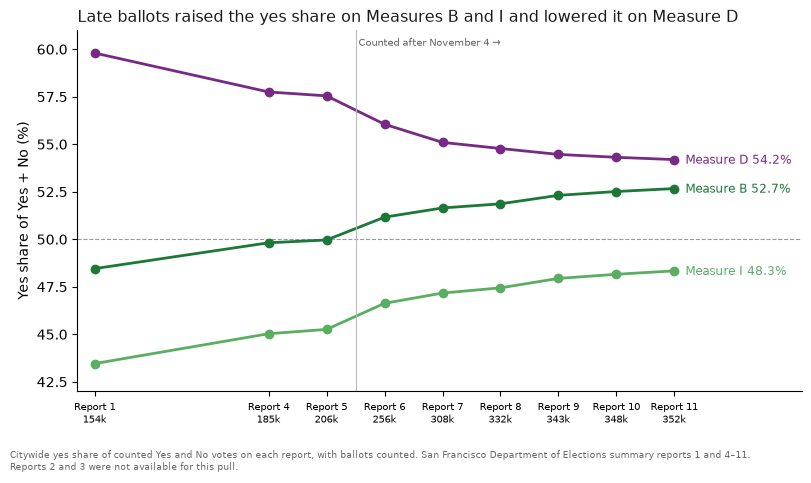

Measure B                                       Measure I  \
choice ballots_counted yes_pct    margin added_yes_pct ballots_counted   
report                                                                   
1               154364   48.46 -4,424.00           NaN          154364   
4               185032   49.82   -630.00         56.85          185032   
5               206320   49.96   -144.00         51.24          206320   
6               256382   51.16  5,499.00         56.17          256382   
7               307917   51.65  9,337.00         54.07          307917   
8               332467   51.87 11,406.00         54.65          332467   
9               342844   52.31 14,526.00         68.12          342844   
10              347938   52.51 16,016.00         66.98          347938   
11              351502   52.67 17,163.00         69.47          351502   

                                              Measure D                    \
choice yes_pct     margin added_yes_pct ballots_counted yes_pct    margin   
report                                                                      
1        43.46 -18,722.00           NaN          154364   59.80 28,733.00   
4        45.03 -16,981.00         53.14          185032   57.75 27,127.00   
5        45.26 -18,064.00         47.24          206320   57.54 29,439.00   
6        46.63 -15,912.00         52.35          256382   56.05 29,290.00   
7        47.17 -16,041.00         49.86          307917   55.10 29,606.00   
8        47.44 -15,614.00         50.96          332467   54.78 29,921.00   
9        47.94 -12,947.00         65.49          342844   54.46 28,762.00   
10       48.16 -11,735.00         63.80          347938   54.31 28,170.00   
11       48.34 -10,686.00         67.93          351502   54.19 27,642.00   

                      
choice added_yes_pct  
report                
1                NaN  
4              47.17  
5              55.75  
6              49.84  
7              50.33  
8              50.69  
9              43.45  
10             43.45  
11             41.27

In [4]:
tables = {m: sf.measure_trend(trend, m) for m in ["Measure B", "Measure I", "Measure D"]}
bands = {"Measure B": [(54.1, 56.2), (67.0, 69.5)], "Measure I": [(49.9, 52.4), (63.8, 67.9)],
         "Measure D": [(49.8, 50.7), (41.3, 43.4)]}
for measure, ((mid_low, mid_high), (end_low, end_high)) in bands.items():
    added = tables[measure]["added_yes_pct"]
    check.number(f"{measure}: lowest added yes share, November 5 to 7 reports", mid_low, added.loc[6:8].min())
    check.number(f"{measure}: highest added yes share, November 5 to 7 reports", mid_high, added.loc[6:8].max())
    check.number(f"{measure}: lowest added yes share, November 8 to 10 reports", end_low, added.loc[9:11].min())
    check.number(f"{measure}: highest added yes share, November 8 to 10 reports", end_high, added.loc[9:11].max())

b, i, d = tables["Measure B"], tables["Measure I"], tables["Measure D"]
first_lead = int(b.index[b["margin"] > 0][0])
check.fact("Measure B first led on", "Report 6 (November 5)", f"Report {first_lead}",
           first_lead == 6 and bool((b.loc[6:, "margin"] > 0).all()))
check.number("Ballots added by the November 5 report", 50062, b.loc[6, "ballots_added"], 0)
check.number("Measure B lead, votes", 17163, b["margin"].iloc[-1], 0)
check.fact("Measure I trailed on every report", "every report", f"{int((i['margin'] < 0).sum())} of {len(i)}",
           bool((i["margin"] < 0).all()))
check.number("Measure I No lead on November 4, votes", 18064, -i.loc[5, "margin"], 0)
check.number("Measure I No lead now, votes", 10686, -i["margin"].iloc[-1], 0)
check.fact("Measure D led on every report", "every report", f"{int((d['margin'] > 0).sum())} of {len(d)}",
           bool((d["margin"] > 0).all()))
check.number("Measure D yes share on election night, percent", 59.80, d.loc[1, "yes_pct"], 2)
check.number("Measure D yes share now, percent", 54.19, d["yes_pct"].iloc[-1], 2)
sf.late_count_chart(trend, None)
pd.concat({m: t[["ballots_counted", "yes_pct", "margin", "added_yes_pct"]] for m, t in tables.items()}, axis=1).round(2)

## What it would take to flip

The Department has not said how many ballots remain. This assumes the rest break like the
votes added by the last two reports.

In [5]:
def last_two(table):
    added = table[["YES", "NO"]].iloc[-1] - table[["YES", "NO"]].iloc[-3]
    return added["YES"] / added.sum()

i_rate, d_rate = last_two(i), last_two(d)
i_needed = -i["margin"].iloc[-1] / (2 * i_rate - 1)
i_per_ballot = (i["YES"].iloc[-1] + i["NO"].iloc[-1]) / i["ballots_counted"].iloc[-1]
d_needed = d["margin"].iloc[-1] / (1 - 2 * d_rate)
check.number("Measure I yes share of votes added by the last two reports, percent", 65.5, 100 * i_rate)
check.number("Measure I votes needed to pull even, thousands", 34.6, i_needed / 1000)
check.number("Measure I votes per 100 ballots", 91.5, 100 * i_per_ballot)
check.number("Ballots needed for Measure I, thousands", 37.8, i_needed / i_per_ballot / 1000)
check.number("Ballots added by the second-to-last report", 5094, b["ballots_added"].iloc[-2], 0)
check.number("Ballots added by the last report", 3564, b["ballots_added"].iloc[-1], 0)
check.number("Measure D yes share of votes added by the last two reports, percent", 42.6, 100 * d_rate)
check.number("Measure D votes needed to fall behind, thousands", 186, d_needed / 1000, 0)

## Numbers the memo quotes

In [6]:
check.report();

,claim,memo,computed,matches
0,Ballots counted by November 4,"206,320","206,320",yes
1,Ballots counted since November 4,"145,182","145,182",yes
2,"Measure B yes share through November 4, percent",49.96,49.96,yes
3,"Measure B yes share of votes counted since, percent",56.6,56.6,yes
4,"Measure I yes share through November 4, percent",45.3,45.3,yes
5,"Measure I yes share of votes counted since, percent",52.8,52.8,yes
6,"Measure D yes share through November 4, percent",57.5,57.5,yes
7,"Measure D yes share of votes counted since, percent",49.3,49.3,yes
8,"Measure G yes share through November 4, percent",36.4,36.4,yes
9,"Measure G yes share of votes counted since, percent",31.3,31.3,yes


All 47 numbers checked match the memo.
